# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv(r"C:\Users\janah\Desktop\NLP\Lab11\Lab_11_QnA_Dataset.csv")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

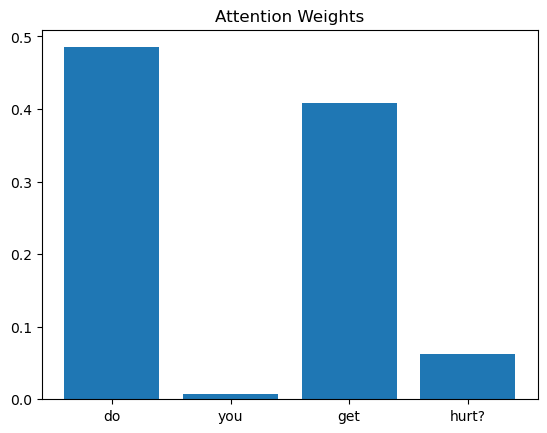

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

## Select Three Questions

In [7]:
# Select three questions from the dataset
selected_indices = [0, 1, 2]

for i in selected_indices:
    print(f"Question {i+1}: {df['question'].iloc[i]}")


Question 1: do you get hurt?
Question 2: do you have fingers?
Question 3: do you ever breathe


## Generate Attention Weights

In [8]:
# Get attention weights for the selected questions
model.eval()

with torch.no_grad():
    predictions, weights = model(X[selected_indices])


## Visualize Attention Weights

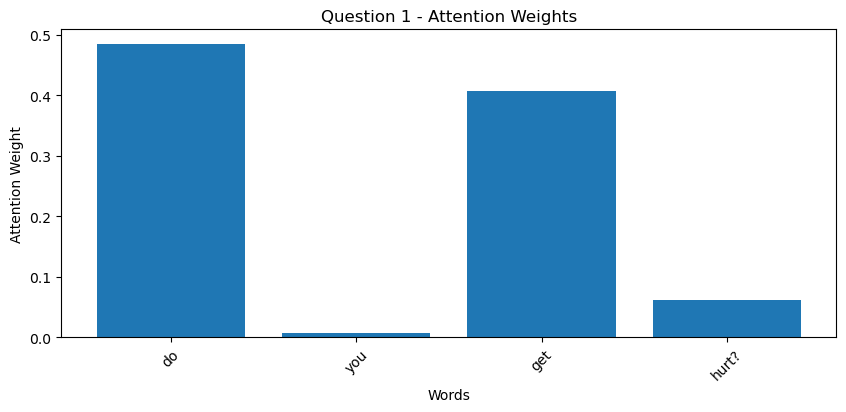

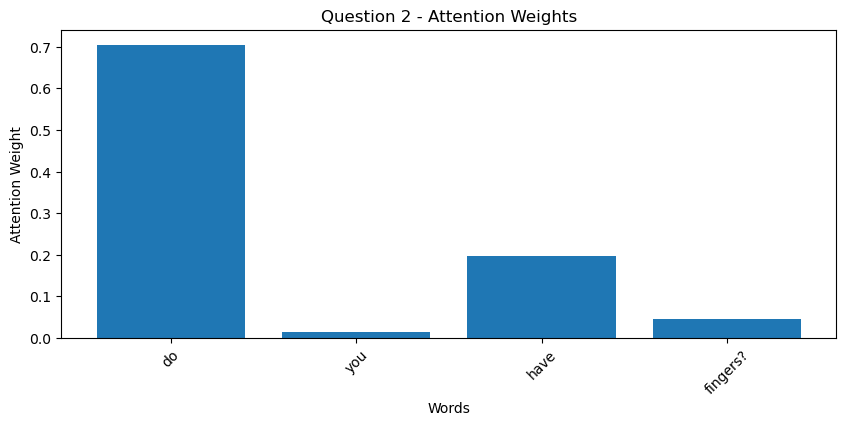

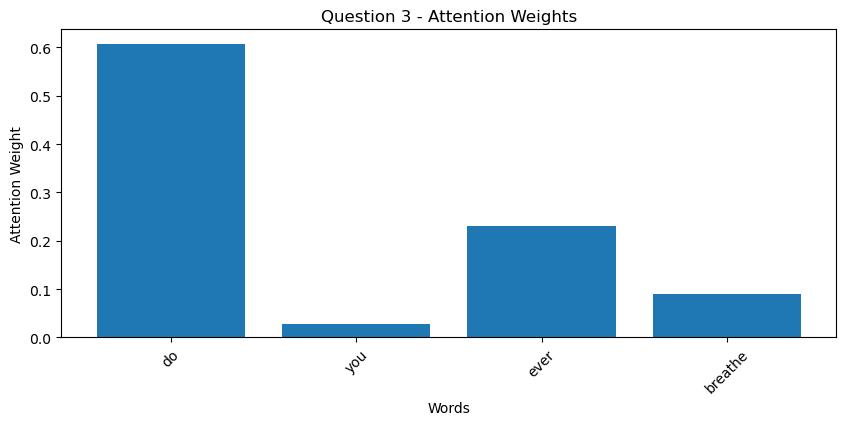

In [9]:
# Plot attention weights for each question
for j, i in enumerate(selected_indices):
    words = df["question"].iloc[i].split()
    attention = weights[j, :len(words)].tolist()

    plt.figure(figsize=(10, 4))
    plt.bar(words, attention)
    plt.title(f"Question {j+1} - Attention Weights")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.show()

## Identify the Highest Attention Word

In [10]:
# Find the word with the highest attention weight
for j, i in enumerate(selected_indices):
    words = df["question"].iloc[i].split()
    attention = weights[j, :len(words)]

    max_index = torch.argmax(attention).item()

    print(f"Question {j+1}: {df['question'].iloc[i]}")
    print(f"Highest attention word: {words[max_index]}")
    print(f"Attention weight: {attention[max_index].item():.4f}")
    print()


Question 1: do you get hurt?
Highest attention word: do
Attention weight: 0.4851

Question 2: do you have fingers?
Highest attention word: do
Attention weight: 0.7058

Question 3: do you ever breathe
Highest attention word: do
Attention weight: 0.6070



- The model gave the highest attention weight to "do" in all three questions. However, words like "hurt", "fingers", and "breathe" are more important for understanding the meaning of each question. This suggests that the model focuses more on the question structure than its specific meaning.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

## Find Two Similar Questions

In [11]:
# Find two questions with the same answer ID
similar_pairs = df.groupby("answer_id").filter(
    lambda group: group["question"].nunique() >= 2
)

group = next(iter(similar_pairs.groupby("answer_id")))[1]

selected_indices = group.index[:2].tolist()

for i in selected_indices:
    print(f"Question: {df.loc[i, 'question']}")


Question: do you get hurt?
Question: do you have fingers?


## Generate Attention Weights

In [12]:
# Generate attention weights for both questions
model.eval()

with torch.no_grad():
    predictions, weights = model(X[selected_indices])

print("Attention weights generated successfully!")


Attention weights generated successfully!


## Visualize Attention Weights

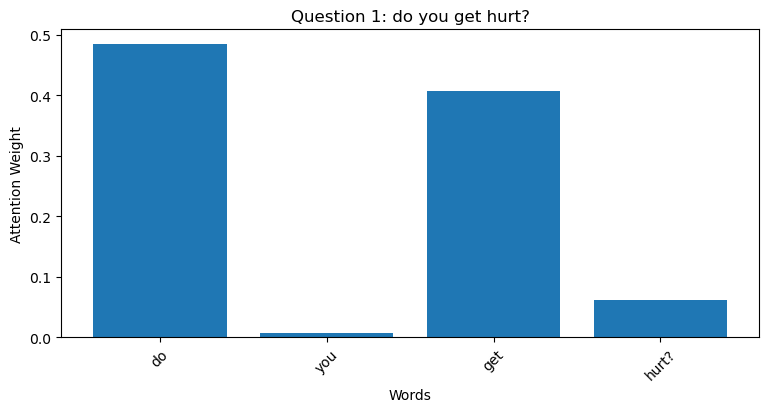

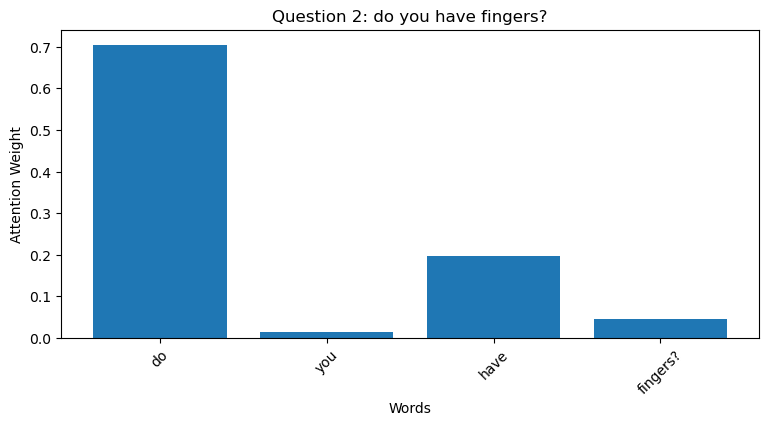

In [13]:
# Visualize attention for both questions
for j, i in enumerate(selected_indices):
    words = df.loc[i, "question"].split()
    attention = weights[j, :len(words)].tolist()

    plt.figure(figsize=(9, 4))
    plt.bar(words, attention)
    plt.title(f"Question {j+1}: {df.loc[i, 'question']}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.show()


## Compare Highest Attention Words

In [14]:
# Compare the highest attention words
for j, i in enumerate(selected_indices):
    words = df.loc[i, "question"].split()
    attention = weights[j, :len(words)]

    max_index = torch.argmax(attention).item()

    print(f"Question {j+1}: {df.loc[i, 'question']}")
    print(f"Highest attention word: {words[max_index]}")
    print(f"Attention weight: {attention[max_index].item():.4f}")
    print()


Question 1: do you get hurt?
Highest attention word: do
Attention weight: 0.4851

Question 2: do you have fingers?
Highest attention word: do
Attention weight: 0.7058



- The model focused on "do" in both questions, with attention weights of 0.4851 and 0.7058. This suggests that the model pays more attention to the question structure than to the words that describe its meaning.